# 01 · Exploratory data analysis
AI4I 2020 predictive-maintenance data (synthetic). Quality checks use the full raw file; distribution analysis uses the **training split only** so that nothing is learned from validation/test rows.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20)
from ml import config
report = lambda name: json.loads((config.REPORTS_DIR / name).read_text())

In [2]:
from ml.preprocessing.data import load_raw, quality_report
raw = load_raw()
raw.head()

,udi,product_id,type,air_temp_k,process_temp_k,rotational_speed_rpm,torque_nm,tool_wear_min,machine_failure,twf,hdf,pwf,osf,rnf
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
q = quality_report(raw)
keys = ['n_rows', 'missing_values_total', 'duplicate_rows', 'failure_rate',
        'imbalance_ratio', 'failure_mode_counts', 'type_counts', 'label_consistency']
{k: q[k] for k in keys}

{'n_rows': 10000, 'missing_values_total': 0, 'duplicate_rows': 0, 'failure_rate': 0.0339, 'imbalance_ratio': 28.5, 'failure_mode_counts': {'twf': 46, 'hdf': 115, 'pwf': 95, 'osf': 98, 'rnf': 19}, 'type_counts': {'L': 6000, 'M': 2997, 'H': 1003}, 'label_consistency': {'failure_without_mode': 9, 'mode_without_failure': 18, 'mode_without_failure_by_mode': {'twf': 0, 'hdf': 0, 'pwf': 0, 'osf': 0, 'rnf': 18}, 'failures_with_multiple_modes': 24}}

**Label consistency.** 9 failures carry no mode flag and 18 RNF flags have no failure. The official `Machine failure` column is kept as the target; nothing is relabelled.

In [4]:
pd.DataFrame(q['outliers_iqr']).T

,lower_fence,upper_fence,n_outliers,pct_outliers
air_temp_k,293.50,306.30,0.0,0.00
process_temp_k,305.35,314.55,0.0,0.00
rotational_speed_rpm,1139.50,1895.50,418.0,4.18
torque_nm,12.80,67.20,69.0,0.69
tool_wear_min,-110.50,325.50,0.0,0.00


## Are the outliers errors?

In [5]:
eda = report('eda_summary.json')
eda['outlier_check']

{'rotational_speed_rpm': {'n_outliers': 255, 'failure_rate_outliers': 0.0745, 'failure_rate_rest': 0.0322, 'power_w_range_outliers': [1264.1, 5074.6]}, 'torque_nm': {'n_outliers': 34, 'failure_rate_outliers': 0.9706, 'failure_rate_rest': 0.0287, 'power_w_range_outliers': [1264.1, 10233.2]}, 'rpm_torque_spearman': -0.917}

Torque outliers fail ~97% of the time: they are a real high-stress regime and are kept.

## Which conditions differ between normal and failed machines?

In [6]:
d = pd.DataFrame({k: {'normal_median': v['normal_median'], 'failed_median': v['failed_median'],
                   'SMD': v['standardized_mean_difference']} for k, v in eda['distributions'].items()}).T
d.sort_values('SMD', key=abs, ascending=False)

,normal_median,failed_median,SMD
strain_nm_min,3934.250,7648.200,0.848
torque_nm,39.800,53.650,0.823
power_w,6241.057,7557.614,0.735
temp_diff_k,9.800,9.200,-0.570
tool_wear_min,107.000,153.500,0.517
air_temp_k,300.000,301.550,0.432
process_temp_k,310.000,310.500,0.183
rotational_speed_rpm,1507.000,1366.000,-0.181


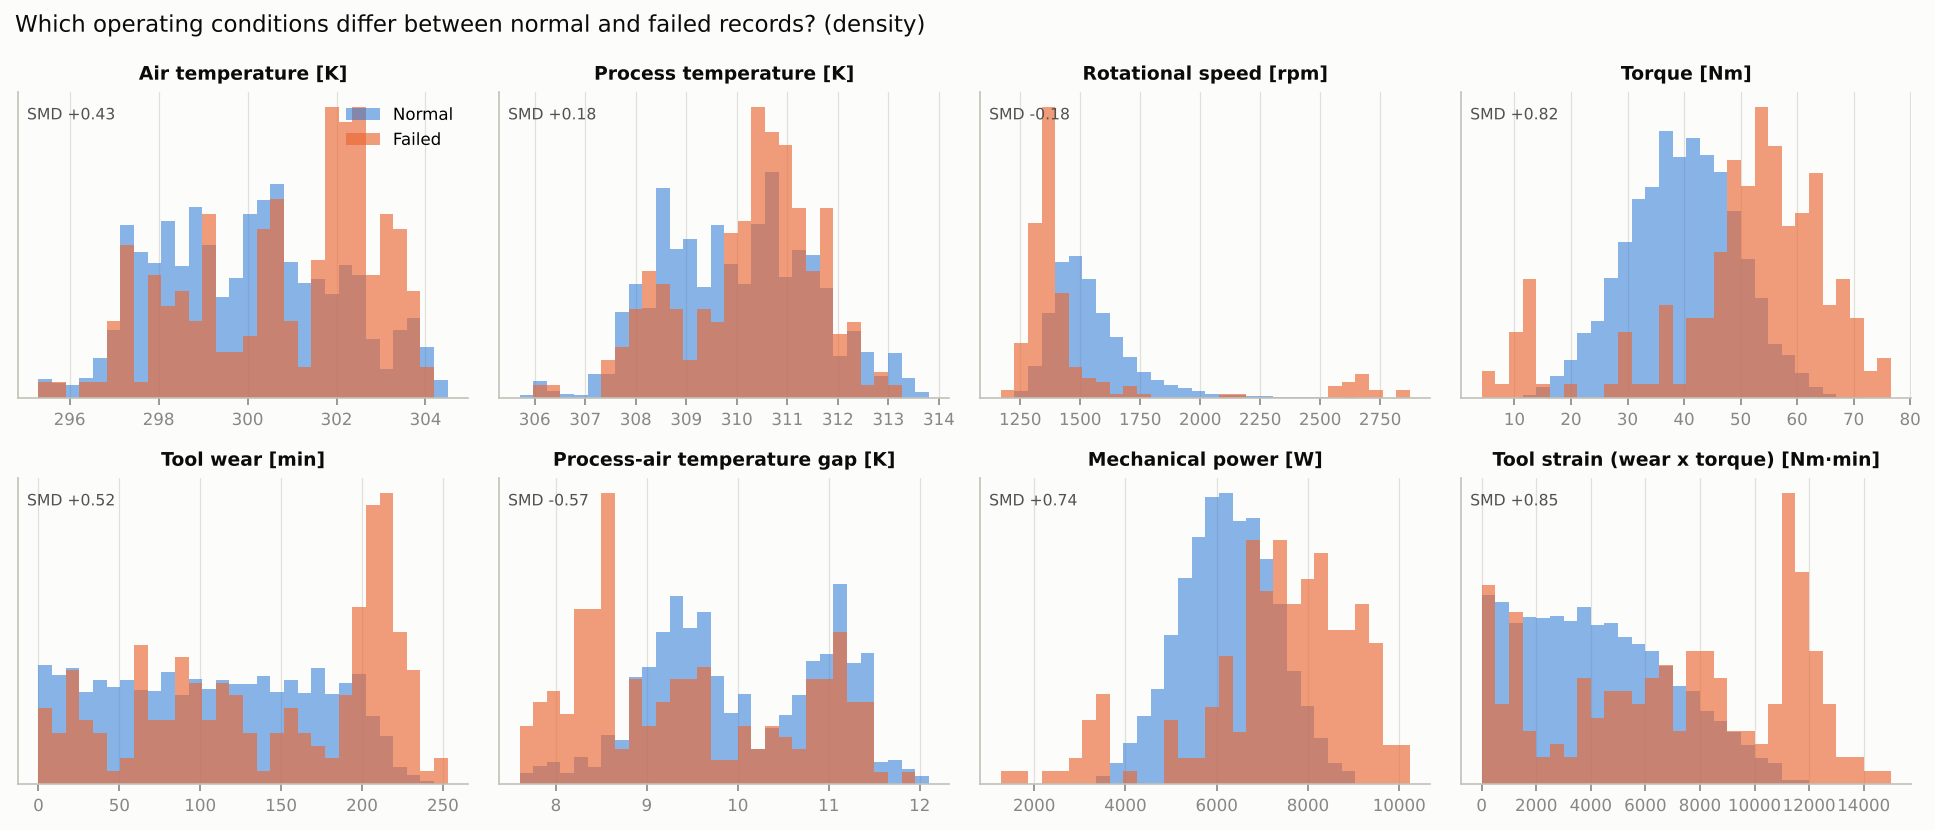

In [7]:
from IPython.display import Image
Image(str(config.FIGURES_DIR / '02_distributions_by_failure.png'))

## Where does each failure mode occur?

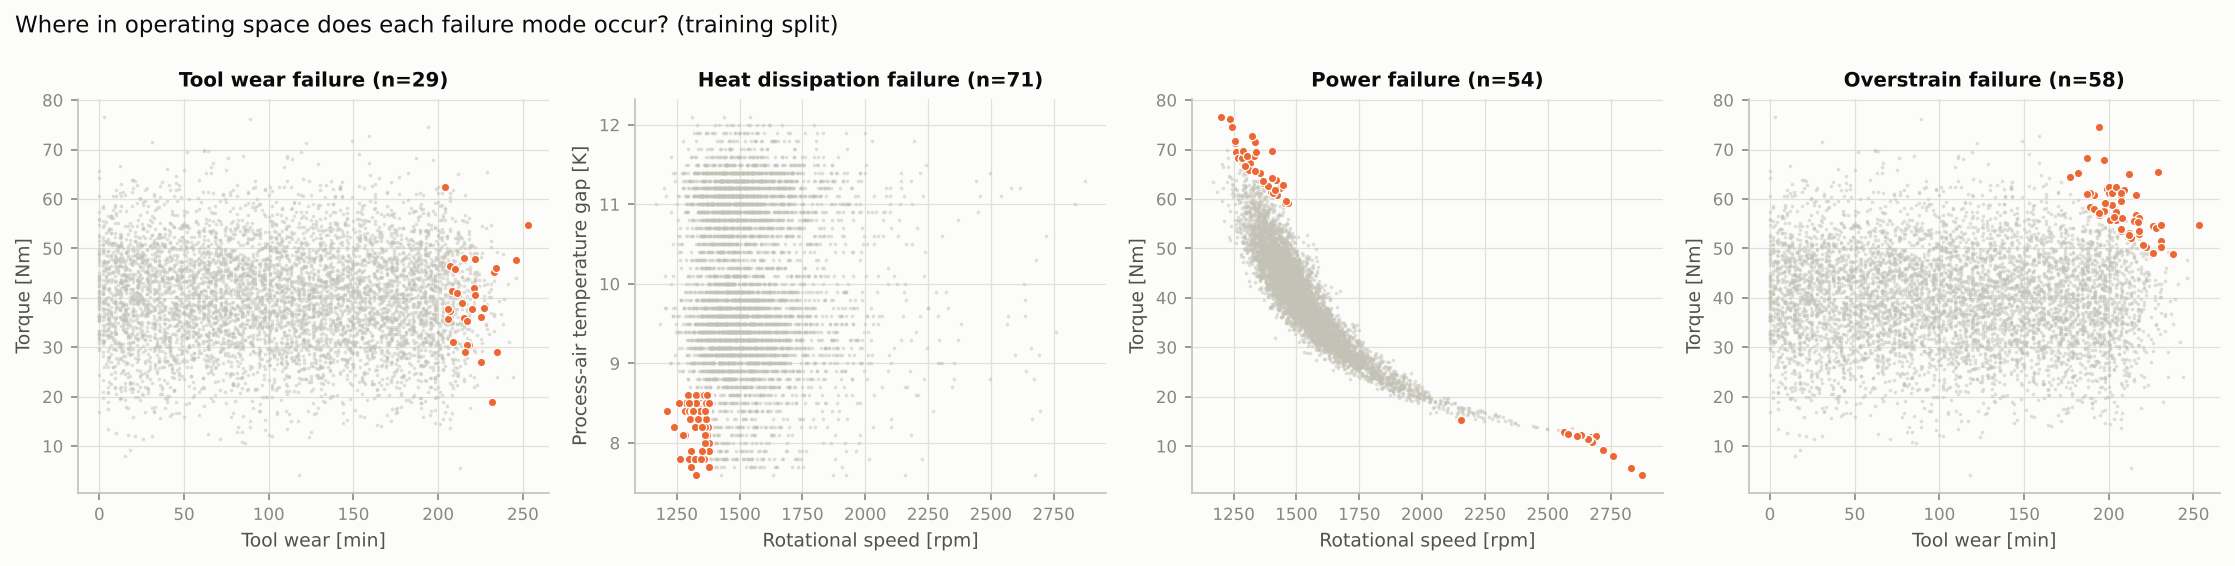

In [8]:
Image(str(config.FIGURES_DIR / '04_failure_mode_regions.png'))

Each mode occupies a distinct region: HDF at low speed with a small temperature gap, PWF at both power extremes, OSF at high wear x torque, TWF at high tool wear. This motivates the engineered features in notebook 02.

In [9]:
pd.DataFrame(eda['failure_rate_by_type']).T

,rate,n,failures,ci_low,ci_high
L,0.0384,3591.0,138.0,0.0326,0.0452
M,0.0298,1811.0,54.0,0.0229,0.0387
H,0.0201,598.0,12.0,0.0115,0.0347
